# 14 · v2: gộp stay thành "nơi" bằng DBSCAN trước khi chấm home/office

v1 chấm **từng stay** riêng lẻ. Notebook 12 và 13 chỉ ra giới hạn của cách này: nhiều đêm trọn ở cùng một nhà **hoà nhau** (mỗi đêm đúng 600 phút trong khung), nên luật phá hoà chọn chứ không phải bằng chứng. Kết quả là v1 chỉ ổn định hơn đoán ngẫu nhiên một chút (home 41% so với 27%, office 42% so với 23%), và thêm dữ liệu cũng không giúp. Chấm theo **vùng 200 m quanh mỗi stay** (chỉ để so sánh) đạt 63% / 63%, và lên tới 94% khi user có nhiều dữ liệu.

v2 (spec checkpoint 2) gộp các stay gần nhau thành một **nơi** bằng DBSCAN, rồi chấm từng nơi bằng **tổng số phút trong khung** của mọi stay thuộc nơi đó. Khung giờ giữ nguyên như v1 (home 22–08 h mọi ngày, office 09–18 h thứ 2–6, giờ địa phương; notebook 12).

**Câu hỏi:**
1. Chọn `eps` (bán kính láng giềng) và `min_samples` thế nào? Config hiện có `eps = 100 m`, `min_samples = 3`, chưa có bằng chứng.
2. `min_samples` nên đếm **số stay** (DBSCAN thuần) hay **số ngày khác nhau**? Ba stay trong cùng một buổi chiều không phải bằng chứng rằng đó là một nơi quen thuộc; ba đêm khác nhau thì là. Notebook so cả hai.
3. v2 cần luật "unknown" nào (notebook 13 đề nghị đo lại trên nơi, vì ở đó lượng dữ liệu **có** ích)?

**Không có nhãn home/office**, nên chỉ số chính là **độ ổn định split-half** của notebook 13: chia ngày chẵn / ngày lẻ, chạy cùng luật trên từng nửa, xem hai nửa có chọn cùng một chỗ không (tâm hai nơi thắng cách nhau ≤ 200 m). Mọi CI bootstrap theo nhóm user dùng chung file (notebook 11).

**Bẫy của chỉ số này:** `eps` càng lớn thì cụm càng to. Ở cực đoan, mỗi user chỉ còn một cụm khổng lồ và hai nửa luôn "chọn cùng một chỗ". Vì vậy độ ổn định phải đọc cùng với **độ rộng của cụm** và tỉ lệ home và office **rơi vào cùng một cụm**. Cả hai tăng lên là dấu hiệu DBSCAN đang nối chuỗi (chaining) các nơi khác nhau.

Notebook 12 có so với "nơi lõi ban đêm / ban ngày", nhưng nơi lõi được định nghĩa bằng chính vùng 200 m, nên dùng nó để chấm v2 sẽ tự chứng minh. Notebook này không dùng chỉ số đó.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

NOTEBOOK = "14_place_clustering"
DATA_DIR = Path("../data/raw")
OUT_DIR = Path("outputs") / NOTEBOOK
FIG_DIR, TABLE_DIR, CACHE_DIR, MAP_DIR = (OUT_DIR / d for d in ("figures", "tables", "cache", "maps"))
for d in (FIG_DIR, TABLE_DIR, CACHE_DIR, MAP_DIR):
    d.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(Path("../src").resolve()))
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.cluster import DBSCAN

from gps.models.heuristic import HeuristicClassifier

STAY_DIR = Path("../data/processed/staypoints")
SHARED_PAIRS = Path("outputs/11_shared_recordings/tables/shared_pairs.csv")
NEAR_M = 200                     # "cùng một chỗ" = bán kính stay-point (notebook 07)
EARTH_M = 6_371_008.8
TYPES = {"home": "home_min", "office": "office_min"}
DAYS_COL = {"home": "nights", "office": "office_days"}
EPS_GRID = [50, 100, 150, 200, 300, 500]
MS_GRID = [2, 3, 5]
CONFIGS = ([(eps, 1, "stays") for eps in EPS_GRID]          # min_samples = 1: hai cách đếm trùng nhau
           + [(eps, ms, mode) for mode in ("stays", "days") for ms in MS_GRID for eps in EPS_GRID])
MS_COLORS = {1: "#8a8980", 2: "#2a78d6", 3: "#eb6834", 5: "#1baf7a"}
REF_COLORS = {"v1": "#5f5e58", "area200": "#b0afa8", "chance": "#8a8980"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6})
clf = HeuristicClassifier()
rng = np.random.default_rng(14)

## 1. Dữ liệu
Giống notebook 13: stay ≥ 30 phút của pipeline, số phút trong khung tính bằng **chính hàm** `HeuristicClassifier.window_minutes` của `src/`, `nights` / `office_days` là các đêm / ngày thứ 2–6 mà stay có ít nhất 1 phút trong khung, và nhóm user dùng chung file để bootstrap.

**"Ngày" của một stay** khi đếm `min_samples` theo số ngày là **ngày địa phương lúc đến**. Hai stay của cùng một đêm, một đến lúc 23 h và một lúc 01 h, bị tính là hai ngày; trường hợp này hiếm vì stay ≥ 30 phút ở cùng chỗ thường được nối thành một.

In [2]:
paths = sorted(STAY_DIR.glob("user_*.parquet"))
stays = pd.concat([pd.read_parquet(p) for p in paths], ignore_index=True)
stays["user_id"] = stays["user_id"].astype(str).str.zfill(3)
stays = stays[stays["duration_minutes"] >= clf.min_duration_minutes].reset_index(drop=True)

DAY = pd.Timedelta(days=1)


def window_days(arrival, departure, start, end, weekdays=None):
    """Các ngày d (date) mà [arrival, departure) chạm khung mở lúc start giờ ngày d."""
    out = []
    d = (arrival - DAY).normalize()
    while d <= departure:
        opens = d + pd.Timedelta(hours=start)
        closes = d + pd.Timedelta(hours=end if end > start else end + 24)
        if min(departure, closes) > max(arrival, opens) and (weekdays is None or d.dayofweek in weekdays):
            out.append(d.date())
        d += DAY
    return out


rows = [(*clf.window_minutes(a.to_pydatetime(), d.to_pydatetime()),
         window_days(a, d, clf.home_hour_start, clf.home_hour_end),
         window_days(a, d, clf.office_hour_start, clf.office_hour_end, clf.work_days))
        for a, d in zip(stays["arrival_local"], stays["departure_local"])]
stays["home_min"], stays["office_min"], stays["nights"], stays["office_days"] = map(list, zip(*rows))
stays["day"] = stays["arrival_local"].to_numpy("datetime64[D]").astype(np.int64)

pairs = pd.read_csv(SHARED_PAIRS, dtype=str)
parent = {}


def root(x):
    parent.setdefault(x, x)
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x


for a, b in zip(pairs["user_a"], pairs["user_b"]):
    parent[root(a)] = root(b)
GROUP = {u: root(u) for u in stays["user_id"].unique()}
USERS = {u: g.reset_index(drop=True) for u, g in stays.groupby("user_id")}


def dist_m(lat1, lon1, lat2, lon2):
    la1, lo1, la2, lo2 = map(np.radians, (lat1, lon1, lat2, lon2))
    h = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return 2 * EARTH_M * np.arcsin(np.sqrt(h))


DIST = {u: dist_m(g["lat"].to_numpy()[:, None], g["lon"].to_numpy()[:, None], g["lat"].to_numpy(), g["lon"].to_numpy())
        .astype(np.float32) for u, g in USERS.items()}
print(f"Users with >= 1 stay: {len(USERS)}; stays >= 30 min: {len(stays):,}; "
      f"independent groups: {len(set(GROUP.values()))}; largest user: {max(len(g) for g in USERS.values()):,} stays")

Users with >= 1 stay: 174; stays >= 30 min: 18,597; independent groups: 140; largest user: 1,921 stays


## 2. Luật v2 được thử
**DBSCAN trên từng user** (khoảng cách haversine giữa tâm các stay):
- Một stay là **lõi** khi trong bán kính `eps` quanh nó (kể cả chính nó) có ít nhất `min_samples` stay (`stays`), hoặc có stay của ít nhất `min_samples` **ngày khác nhau** (`days`).
- Các stay lõi cách nhau ≤ `eps` nối thành một cụm; stay không lõi nhưng nằm trong `eps` của một stay lõi (stay biên) gia nhập cụm của stay lõi **gần nhất**.
- Stay không thuộc cụm nào (nhiễu) **không bị bỏ**: mỗi stay nhiễu là một nơi riêng. Như vậy v2 không loại dữ liệu nào, và việc một nơi chỉ có một lần ghé được xử lý bằng luật "unknown" (mục 5), giống v1.
- `min_samples = 1` nghĩa là mọi stay đều là lõi: cụm là các thành phần liên thông ở khoảng cách `eps` (single-linkage), hai cách đếm trùng nhau.

**Chấm điểm:** điểm home của một nơi = tổng số phút trong khung home của mọi stay thuộc nơi đó (office tương tự). Nơi thắng = điểm cao nhất; hoà thì tổng thời lượng dài hơn, rồi đến sớm hơn. Vị trí của nơi = tâm các stay, có trọng số theo thời lượng. Confidence = điểm của nơi thắng / tổng điểm của user (đúng định nghĩa của v1, áp lên nơi).

Ô dưới kiểm tra rằng cách cài đặt này cho **cùng các stay lõi và cùng phân hoạch lõi** như `sklearn.cluster.DBSCAN` (metric haversine) ở chế độ `stays`. Stay biên nằm giữa hai cụm có thể được gán khác (sklearn gán theo thứ tự duyệt, ở đây theo stay lõi gần nhất), nên chỉ so stay lõi và tập nhiễu.

In [3]:
def dbscan(D, days, eps, min_samples, mode):
    """Nhãn cụm (>= 0) hoặc -1 (nhiễu) cho mỗi stay; D là ma trận khoảng cách (m)."""
    N = D <= eps
    if mode == "stays" or min_samples == 1:
        count = N.sum(1)
    else:
        _, d_idx = np.unique(days, return_inverse=True)
        onehot = np.zeros((len(days), d_idx.max() + 1), np.float32)   # float: matmul qua BLAS
        onehot[np.arange(len(days)), d_idx] = 1
        count = ((N.astype(np.float32) @ onehot) > 0).sum(1)
    core = count >= min_samples
    labels = np.full(len(D), -1)
    if core.any():
        ci = np.flatnonzero(core)
        _, comp = connected_components(csr_matrix(N[np.ix_(ci, ci)]), directed=False)
        labels[ci] = comp
        border = np.flatnonzero(~core & N[:, ci].any(1))
        if len(border):
            labels[border] = comp[D[np.ix_(border, ci)].argmin(1)]
    return labels, core


def place_ids(labels):
    """Nhiễu -> mỗi stay một nơi riêng; mã nơi liên tục 0..K-1."""
    out = labels.copy()
    noise = out < 0
    out[noise] = out.max(initial=-1) + 1 + np.arange(noise.sum())
    return out


def same_partition(a, b):
    return len(set(zip(a, b))) == len(set(a)) == len(set(b))


bad = 0
for u, g in USERS.items():
    X = np.radians(g[["lat", "lon"]].to_numpy())
    for eps, ms in ((100, 3), (200, 2), (50, 5)):
        ours, core = dbscan(DIST[u], g["day"].to_numpy(), eps, ms, "stays")
        sk = DBSCAN(eps=eps / EARTH_M, min_samples=ms, metric="haversine", algorithm="ball_tree").fit(X)
        sk_core = np.zeros(len(g), bool)
        sk_core[sk.core_sample_indices_] = True
        bad += not ((core == sk_core).all() and ((ours < 0) == (sk.labels_ < 0)).all()
                    and same_partition(ours[core], sk.labels_[core]))
print(f"(user, config) cases where core stays, noise or core partition differ from sklearn: {bad} of {len(USERS) * 3}")

(user, config) cases where core stays, noise or core partition differ from sklearn: 0 of 522


In [4]:
def pick_place(g, pid, kind):
    """Nơi thắng của một loại trên tập stay g với mã nơi pid; None nếu không có ứng viên."""
    m = g[TYPES[kind]].to_numpy()
    if m.max(initial=0) <= 0:
        return None
    K = pid.max() + 1
    dur = g["duration_minutes"].to_numpy()
    score = np.bincount(pid, weights=m, minlength=K)
    tot_dur = np.bincount(pid, weights=dur, minlength=K)
    first = np.full(K, np.iinfo(np.int64).max)
    np.minimum.at(first, pid, g["arrival"].astype("int64").to_numpy())
    cand = np.flatnonzero(score > 0)
    best = cand[np.lexsort((first[cand], -tot_dur[cand], -score[cand]))[0]]
    sel = pid == best
    lat = np.average(g["lat"].to_numpy()[sel], weights=dur[sel])
    lon = np.average(g["lon"].to_numpy()[sel], weights=dur[sel])
    r = dist_m(lat, lon, g["lat"].to_numpy()[sel], g["lon"].to_numpy()[sel])
    return {"lat": lat, "lon": lon, "pid": best, "win_min": score[best], "conf": score[best] / score.sum(),
            "n_stays": int(sel.sum()), "days": len(set().union(*g[DAYS_COL[kind]].to_numpy()[sel])),
            "radius": float(r.max()), "n_cand_places": len(cand)}


def pick_v1(u, g, kind, area=False):
    """v1 (từng stay) hoặc vùng 200 m quanh mỗi stay (chỉ để so sánh), như notebook 13."""
    c = g[g[TYPES[kind]] > 0]
    if c.empty:
        return None
    minutes = c[TYPES[kind]].to_numpy()
    score = (DIST[u][np.ix_(c["_i"], c["_i"])] <= NEAR_M) @ minutes if area else minutes
    i = int(np.lexsort((c["arrival"].astype("int64").to_numpy(), -c["duration_minutes"].to_numpy(), -score))[0])
    return {"lat": c["lat"].iat[i], "lon": c["lon"].iat[i], "win_min": score[i]}


for u, g in USERS.items():
    g["_i"] = np.arange(len(g))

## 3. Quét `eps` × `min_samples` × cách đếm
Với mỗi cấu hình, mỗi user, mỗi loại: chia ngày chẵn / lẻ (`alt_day`, notebook 13), phân cụm **riêng trên từng nửa** (như classifier sẽ làm với dữ liệu nó nhận), chọn nơi thắng, và so tâm hai nơi thắng. Ghi lại thêm, trên **toàn bộ dữ liệu** của user:
- `radius`: khoảng cách xa nhất từ tâm nơi thắng tới một stay của nó (nơi một stay có radius 0);
- `home_is_office`: trong các user có cả home và office, tỉ lệ nơi thắng home và nơi thắng office là **cùng một cụm**. Một số user thật sự ở và làm cùng chỗ (ký túc xá cạnh phòng lab), nên tỉ lệ này không bằng 0. Mốc của mức "thật" là tỉ lệ user mà v1 / vùng 200 m (không gộp cụm) chọn home và office cách nhau ≤ 200 m; phần vượt mốc là do DBSCAN **nối** hai nơi khác nhau.

Mốc so sánh trên cùng các cặp: v1, vùng 200 m, và mốc ngẫu nhiên của notebook 13 (chọn bừa một stay ứng viên ở mỗi nửa). Kết quả được cache vào `cache/`.

In [5]:
def split_masks(g):
    dates = g["arrival_local"].dt.date
    uniq = np.array(sorted(dates.unique()))
    if len(uniq) < 2:
        return {}
    return {"alt_day": (dates.map(lambda x: x.toordinal()) % 2 == 0).to_numpy(),
            "chrono": (dates < uniq[len(uniq) // 2]).to_numpy()}


def cluster(u, g, eps, ms, mode):
    if g.empty:
        return np.zeros(0, int)
    D = DIST[u][np.ix_(g["_i"], g["_i"])]
    return place_ids(dbscan(D, g["day"].to_numpy(), eps, ms, mode)[0])


def compare(a, b):
    return bool(dist_m(a["lat"], a["lon"], b["lat"], b["lon"]) <= NEAR_M)


def run_config(eps, ms, mode, splits=("alt_day",)):
    rows = []
    for u, g in USERS.items():
        pid = cluster(u, g, eps, ms, mode)
        full = {k: pick_place(g, pid, k) for k in TYPES}
        for split, m in split_masks(g).items():
            if split not in splits:
                continue
            ga, gb = g[m], g[~m]
            pa, pb = cluster(u, ga, eps, ms, mode), cluster(u, gb, eps, ms, mode)
            for kind in TYPES:
                a, b = pick_place(ga, pa, kind), pick_place(gb, pb, kind)
                r = {"eps": eps, "ms": ms, "mode": mode, "split": split, "user_id": u, "group": GROUP[u], "type": kind,
                     "found_full": full[kind] is not None, "both_halves": a is not None and b is not None}
                if full[kind] is not None:
                    r.update({f"full_{k}": full[kind][k] for k in ("win_min", "n_stays", "days", "radius", "conf")})
                    r["home_is_office"] = (full["office"] is not None and full["home"] is not None
                                           and full["home"]["pid"] == full["office"]["pid"])
                if r["both_halves"]:
                    r["same"] = compare(a, b)
                    r.update({k: min(a[k], b[k]) for k in ("win_min", "n_stays", "days", "conf")})
                rows.append(r)
    return rows


GRID_CACHE = CACHE_DIR / "grid_alt_day.parquet"
if GRID_CACHE.exists():
    grid = pd.read_parquet(GRID_CACHE)
else:
    grid = pd.DataFrame([r for cfg in CONFIGS for r in run_config(*cfg)])
    grid.to_parquet(GRID_CACHE)

# mốc so sánh trên cùng các cặp (user, loại) có cả hai nửa
ref_rows = []
for u, g in USERS.items():
    for split, m in split_masks(g).items():
        ga, gb = g[m], g[~m]
        for kind in TYPES:
            a, b = pick_v1(u, ga, kind), pick_v1(u, gb, kind)
            if a is None or b is None:
                continue
            ca, cb = ga[ga[TYPES[kind]] > 0], gb[gb[TYPES[kind]] > 0]
            ref_rows.append({"split": split, "user_id": u, "group": GROUP[u], "type": kind,
                             "v1": compare(a, b), "area200": compare(pick_v1(u, ga, kind, True), pick_v1(u, gb, kind, True)),
                             "chance": (DIST[u][np.ix_(ca["_i"], cb["_i"])] <= NEAR_M).mean(),
                             "v1_win_min": min(a["win_min"], b["win_min"])})
ref = pd.DataFrame(ref_rows)
print(f"grid rows: {len(grid):,}; reference pairs: {len(ref)}")

grid rows: 14,196; reference pairs: 536


In [6]:
def boot(d, col="same", n=2000):
    """Trung bình và CI 95%, bootstrap theo nhóm user dùng chung file."""
    gs = d.groupby("group")[col].agg(["sum", "size"])
    s, k = gs["sum"].to_numpy(float), gs["size"].to_numpy(float)
    idx = rng.integers(0, len(gs), (n, len(gs)))
    b = s[idx].sum(1) / k[idx].sum(1)
    return pd.Series({"pairs": int(k.sum()), "stable": s.sum() / k.sum(),
                      "ci_lo": np.quantile(b, 0.025), "ci_hi": np.quantile(b, 0.975)})


REF = {}
for kind, d in ref[ref["split"] == "alt_day"].groupby("type"):
    REF[kind] = {r: boot(d, r)["stable"] for r in ("v1", "area200")} | {"chance": d["chance"].mean()}
print(pd.DataFrame(REF).round(3))


def summarize(grid):
    out = []
    both = grid.groupby(["eps", "ms", "mode", "user_id"])["found_full"].transform("all")
    for (eps, ms, mode, kind), d in grid.groupby(["eps", "ms", "mode", "type"]):
        p = d[d["both_halves"]]
        f = d[d["found_full"]]
        fb = d[both.loc[d.index]]
        multi = f[f["full_n_stays"] > 1]
        out.append({"eps": eps, "ms": ms, "mode": mode, "type": kind, **boot(p.assign(same=p["same"].astype(bool))),
                    "found_full": int(d["found_full"].sum()),
                    "winner_radius_p50": f["full_radius"].median(), "winner_radius_p90": f["full_radius"].quantile(0.9),
                    "winner_radius_max": f["full_radius"].max(),
                    "winner_multi_stay": len(multi) / len(f),
                    "home_is_office": fb["home_is_office"].astype(bool).mean()})
    return pd.DataFrame(out)


# Mốc cho kiểm tra nối chuỗi: với v1 và vùng 200 m (không gộp cụm), bao nhiêu user có nơi home và nơi office
# cách nhau <= 200 m? Đây là mức "ở và làm cùng chỗ" thật, không do DBSCAN gây ra.
ho = {"v1": [], "area200": []}
for u, g in USERS.items():
    picks = {r: [pick_v1(u, g, k, r == "area200") for k in TYPES] for r in ho}
    for r, (h, o) in picks.items():
        if h is not None and o is not None:
            ho[r].append(compare(h, o))
HO_REF = {r: np.mean(v) for r, v in ho.items()}
print(f"Users with both home and office: {len(ho['v1'])}; home and office within {NEAR_M} m: "
      + ", ".join(f"{r} {v:.1%}" for r, v in HO_REF.items()))

summary = summarize(grid)
summary.round(3).to_csv(TABLE_DIR / "grid_summary.csv", index=False)
summary.round(3)

          home  office
v1       0.406   0.415
area200  0.630   0.631
chance   0.272   0.226


Users with both home and office: 150; home and office within 200 m: v1 26.0%, area200 28.0%


,eps,ms,mode,type,pairs,stable,ci_lo,ci_hi,found_full,winner_radius_p50,winner_radius_p90,winner_radius_max,winner_multi_stay,home_is_office
0,50,1,stays,home,138.0,0.594,0.503,0.678,159,34.594,155.800,435.360,0.698,0.182
1,50,1,stays,office,130.0,0.531,0.419,0.630,157,24.247,162.087,345.196,0.637,0.182
2,50,2,days,home,138.0,0.587,0.489,0.675,159,33.341,155.800,435.360,0.660,0.182
3,50,2,days,office,130.0,0.523,0.417,0.632,157,24.247,162.087,345.196,0.618,0.182
4,50,2,stays,home,138.0,0.594,0.504,0.679,159,34.594,155.800,435.360,0.698,0.182
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,500,3,stays,office,130.0,0.615,0.521,0.700,157,369.031,948.507,2244.570,0.815,0.419
80,500,5,days,home,138.0,0.609,0.508,0.698,159,217.965,931.040,2244.570,0.629,0.372
81,500,5,days,office,130.0,0.600,0.496,0.694,157,343.090,917.420,2244.570,0.624,0.372
82,500,5,stays,home,138.0,0.630,0.535,0.720,159,311.527,948.907,2244.570,0.736,0.412


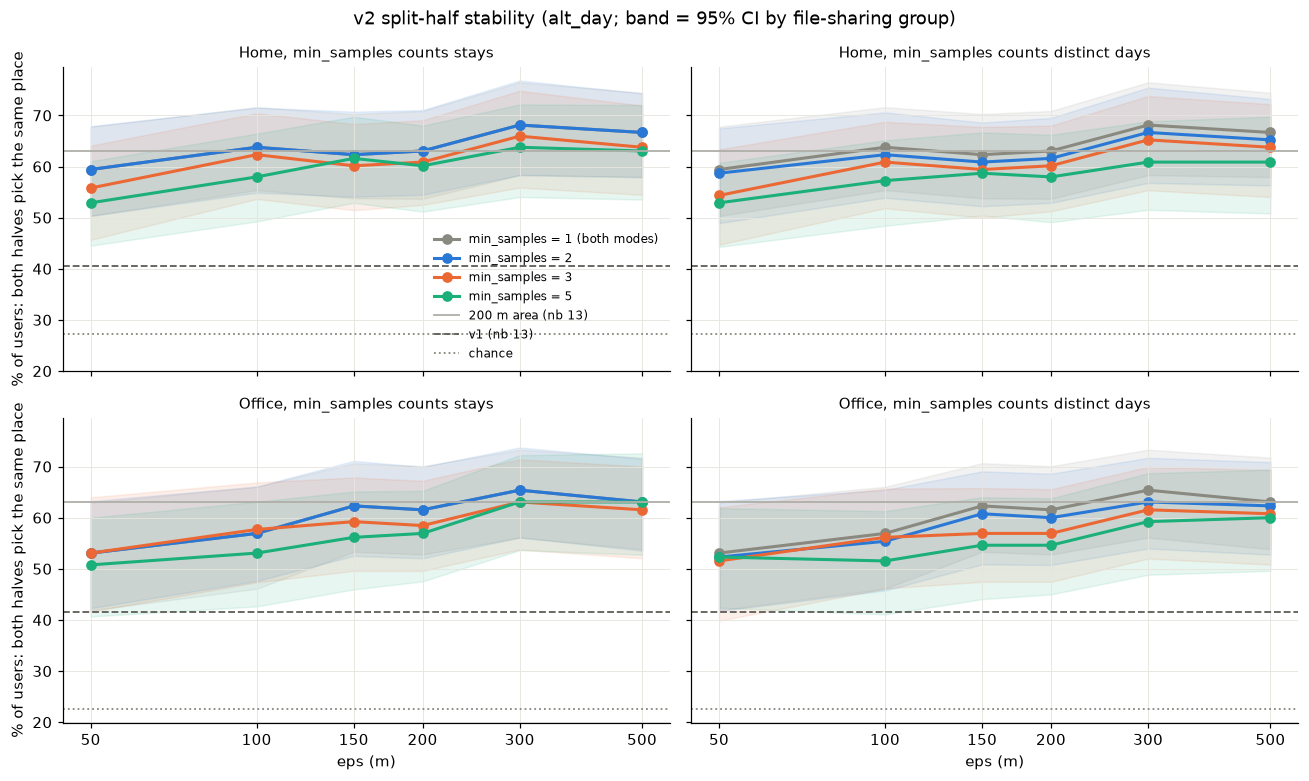

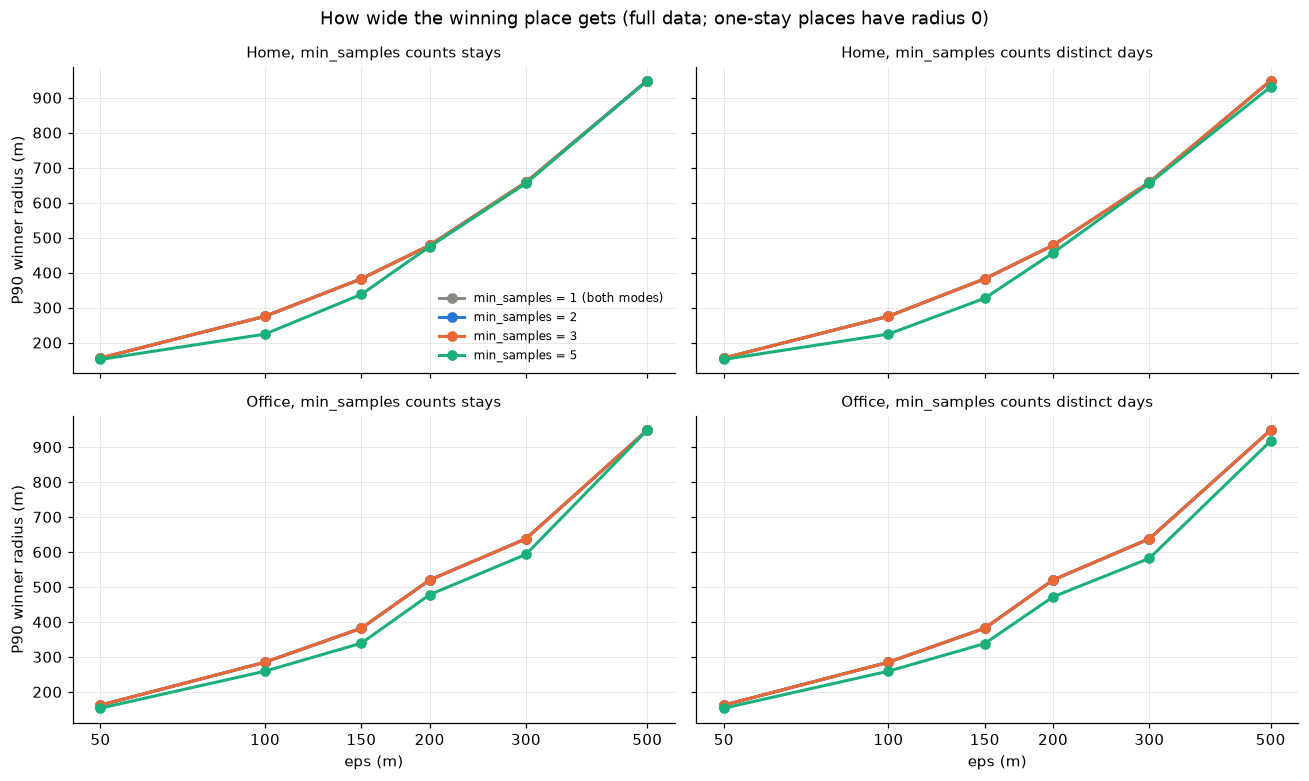

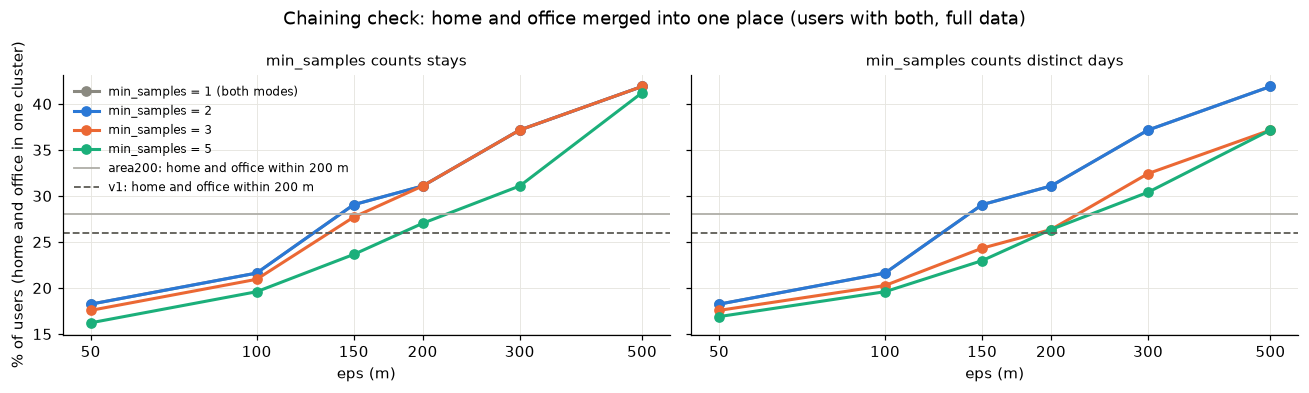

In [7]:
def plot_grid(summary, col, ylabel, title, fname, pct=True, ref_lines=True, types=tuple(TYPES), legend_loc="lower right"):
    fig, axes = plt.subplots(len(types), 2, figsize=(12, 3.6 * len(types)), sharex=True, sharey=True, squeeze=False)
    for row, kind in enumerate(types):
        for c, mode in enumerate(("stays", "days")):
            ax = axes[row, c]
            for ms in [1] + MS_GRID:
                s = summary[(summary["type"] == kind) & (summary["ms"] == ms) & (summary["mode"] == ("stays" if ms == 1 else mode))]
                s = s.sort_values("eps")
                k = 100 if pct else 1
                ax.plot(s["eps"], s[col] * k, marker="o", color=MS_COLORS[ms], linewidth=2,
                        label=f"min_samples = {ms}" + (" (both modes)" if ms == 1 else ""))
                if col == "stable":
                    ax.fill_between(s["eps"], s["ci_lo"] * 100, s["ci_hi"] * 100, color=MS_COLORS[ms], alpha=0.10)
            if col == "home_is_office":
                for r, ls in (("area200", "-"), ("v1", "--")):
                    ax.axhline(HO_REF[r] * 100, color=REF_COLORS[r], linestyle=ls, linewidth=1.2,
                               label=f"{r}: home and office within 200 m")
            if ref_lines:
                for r, ls in (("area200", "-"), ("v1", "--"), ("chance", ":")):
                    ax.axhline(REF[kind][r] * 100, color=REF_COLORS[r], linestyle=ls, linewidth=1.2,
                               label={"area200": "200 m area (nb 13)", "v1": "v1 (nb 13)", "chance": "chance"}[r])
            ax.set_title(("" if len(types) == 1 else f"{kind.capitalize()}, ") + f"min_samples counts {'distinct days' if mode == 'days' else 'stays'}",
                         fontsize=10)
            ax.set_xscale("log")
            ax.set_xticks(EPS_GRID, [str(e) for e in EPS_GRID])
            ax.minorticks_off()
            if row == len(types) - 1:
                ax.set_xlabel("eps (m)")
        axes[row, 0].set_ylabel(ylabel)
    axes[0, 0].legend(frameon=False, fontsize=8, loc=legend_loc)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(FIG_DIR / fname)
    plt.show()


plot_grid(summary, "stable", "% of users: both halves pick the same place",
          "v2 split-half stability (alt_day; band = 95% CI by file-sharing group)", "fig01_stability_grid.png")
plot_grid(summary, "winner_radius_p90", "P90 winner radius (m)",
          "How wide the winning place gets (full data; one-stay places have radius 0)", "fig02_winner_radius_grid.png",
          pct=False, ref_lines=False)
plot_grid(summary, "home_is_office", "% of users (home and office in one cluster)",
          "Chaining check: home and office merged into one place (users with both, full data)",
          "fig03_home_is_office_grid.png", ref_lines=False, types=("home",), legend_loc="upper left")

## 4. Chọn cấu hình

**Đọc Hình 1–3** (bảng `grid_summary.csv`):

- **Độ ổn định không phân biệt được các `eps` từ 100 m trở lên.** Mọi cấu hình nằm trong khoảng 55–68%, ngang vùng 200 m của notebook 13 (63% / 63%), và các CI 95% (rộng khoảng ±9 điểm) chồng lên nhau. Chỉ `eps = 50 m` và `min_samples = 5` thấp hơn thấy rõ. Vậy chỉ số chính chỉ loại được các cấu hình quá chặt, không chọn được một `eps` tối ưu.
- **Độ rộng của nơi thắng tăng đều theo `eps`** (Hình 2): P90 bán kính khoảng 275 m ở 100 m, 382 m ở 150 m, 478 m ở 200 m, 658 m ở 300 m, 949 m ở 500 m. Bán kính lớn nhất vượt 1 km từ `eps = 150 m`.
- **Home và office bị gộp vào cùng một cụm** (Hình 3, trên 150 user có cả hai) tăng từ 18% (50 m) qua 22% (100 m), 29% (150 m), 31% (200 m) lên 37% (300 m) và 42% (500 m). Mốc "ở và làm cùng chỗ" thật (v1 / vùng 200 m chọn home và office cách nhau ≤ 200 m) là 26% / 28%. Ở 100 m DBSCAN còn **tách** một số nơi thật sự chung; ở 150–200 m nó ngang mốc (chênh 2–5 user); từ 300 m nó vượt rõ, tức là bắt đầu **nối** hai nơi khác nhau. Độ ổn định cao hơn một chút ở 300–500 m một phần vì lý do đó: một cụm to thì hai nửa dễ "chọn cùng một chỗ".
- **Đếm `min_samples` theo số ngày không giúp.** Ở cùng `eps` và `min_samples`, cách đếm theo ngày cho độ ổn định bằng hoặc thấp hơn cách đếm theo stay. Nó giảm việc gộp home với office một chút (150 m, `min_samples = 3`: 27,7% → 24,3%), nhưng đổi lại độ ổn định giảm (60% → 59% home, 59% → 57% office; so với `min_samples = 2` theo stay: 62% / 62%).
- **Vì stay nhiễu được giữ lại thành nơi riêng, `min_samples` chỉ còn quyết định việc nối.** Với cách đếm theo stay, `min_samples = 1` và `2` cho kết quả giống hệt (một stay có ít nhất một láng giềng là lõi). `min_samples` cao hơn làm cụm hẹp hơn nhưng cũng kém ổn định hơn.

**Chọn: `eps = 150 m`, `min_samples = 2`, đếm theo stay (DBSCAN thuần).** Luật chọn: `eps` nhỏ nhất mà **cả home lẫn office** đạt mức ổn định của vùng 200 m (62% / 62%; ở 100 m office mới 57%), và việc gộp home với office còn ngang mức thật (29% so với mốc 26–28%). 200 m cho cùng độ ổn định nhưng nơi rộng hơn (P90 478 m). Như các ngưỡng khác của dự án, đây là lựa chọn **hợp lý, không phải tối ưu**: chỉ số chính phẳng trong khoảng 100–200 m.

Bằng chứng "một nơi quen thuộc phải được ghé nhiều ngày" vẫn có giá trị, nhưng đặt ở **luật unknown** (mục 5), không phải trong phân cụm: ở đó nó không làm vỡ cụm mà chỉ quyết định có trả lời hay không.

Bảng dưới so cấu hình đã chọn với v1, vùng 200 m và mốc ngẫu nhiên trên cả hai cách chia (`alt_day` chính, `chrono` có cả chuyển nhà thật).

In [8]:
CHOSEN = (150, 2, "stays")     # (eps m, min_samples, cách đếm)
CMP_CACHE = CACHE_DIR / "chosen_both_splits.parquet"
if CMP_CACHE.exists():
    chosen = pd.read_parquet(CMP_CACHE)
else:
    chosen = pd.DataFrame(run_config(*CHOSEN, splits=("alt_day", "chrono")))
    chosen.to_parquet(CMP_CACHE)

rows = []
for (split, kind), d in chosen[chosen["both_halves"]].groupby(["split", "type"]):
    rows.append({"split": split, "type": kind, "rule": f"v2 {CHOSEN}", **boot(d.assign(same=d["same"].astype(bool)))})
for (split, kind), d in ref.groupby(["split", "type"]):
    for r in ("v1", "area200"):
        rows.append({"split": split, "type": kind, "rule": r, **boot(d, r)})
    rows.append({"split": split, "type": kind, "rule": "chance", "pairs": len(d), "stable": d["chance"].mean()})
compare_tab = pd.DataFrame(rows).sort_values(["split", "type", "stable"], ascending=[True, True, False])
compare_tab.round(3).to_csv(TABLE_DIR / "chosen_vs_v1.csv", index=False)
compare_tab.round(3)

,split,type,rule,pairs,stable,ci_lo,ci_hi
5,alt_day,home,area200,138.0,0.630,0.543,0.711
0,alt_day,home,"v2 (150, 2, 'stays')",138.0,0.623,0.534,0.702
4,alt_day,home,v1,138.0,0.406,0.324,0.500
6,alt_day,home,chance,138.0,0.272,NaN,NaN
8,alt_day,office,area200,130.0,0.631,0.534,0.720
1,alt_day,office,"v2 (150, 2, 'stays')",130.0,0.623,0.530,0.706
7,alt_day,office,v1,130.0,0.415,0.333,0.500
9,alt_day,office,chance,130.0,0.226,NaN,NaN
2,chrono,home,"v2 (150, 2, 'stays')",137.0,0.482,0.403,0.563
11,chrono,home,area200,137.0,0.467,0.386,0.547


## 5. Bằng chứng tối thiểu cho v2: khi nào trả "unknown"?
Notebook 13 đo cho v1 theo bằng chứng của **stay thắng**. Với v2, đơn vị là **nơi thắng**, nên đo lại theo bằng chứng của nơi đó, trên nửa yếu hơn:
- `win_min`: tổng số phút trong khung của nơi thắng;
- `days`: số đêm (home) / số ngày thứ 2–6 (office) có phút trong khung tại nơi thắng. Đây là bản tương ứng của `support` ở v1, nhưng đếm **ngày** chứ không đếm stay;
- `conf`: confidence của v2 (notebook 13 cho thấy confidence của v1 không báo được gì).

Ngưỡng ứng viên là chỗ đường v2 **bắt đầu tách khỏi** mốc ngẫu nhiên, như cách notebook 13 chọn 240 phút và support ≥ 2.

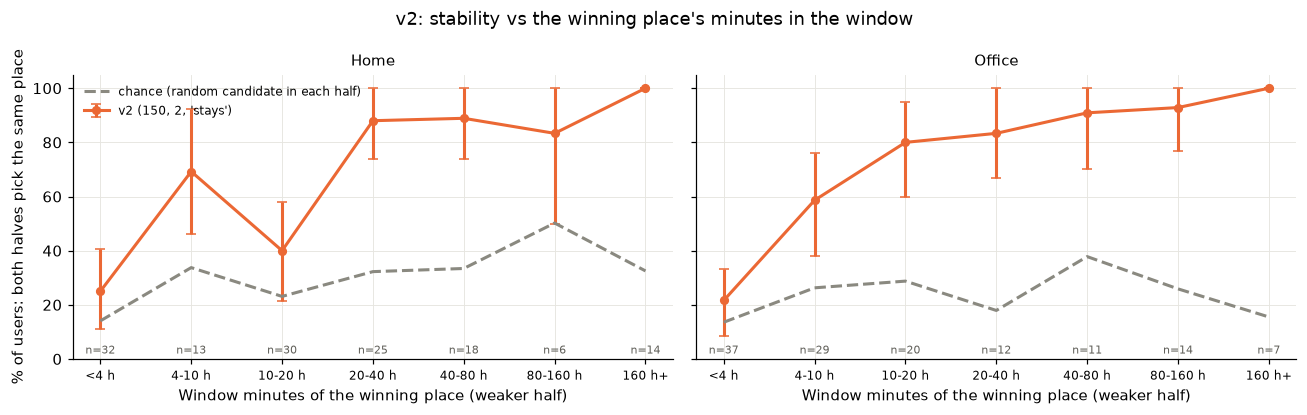

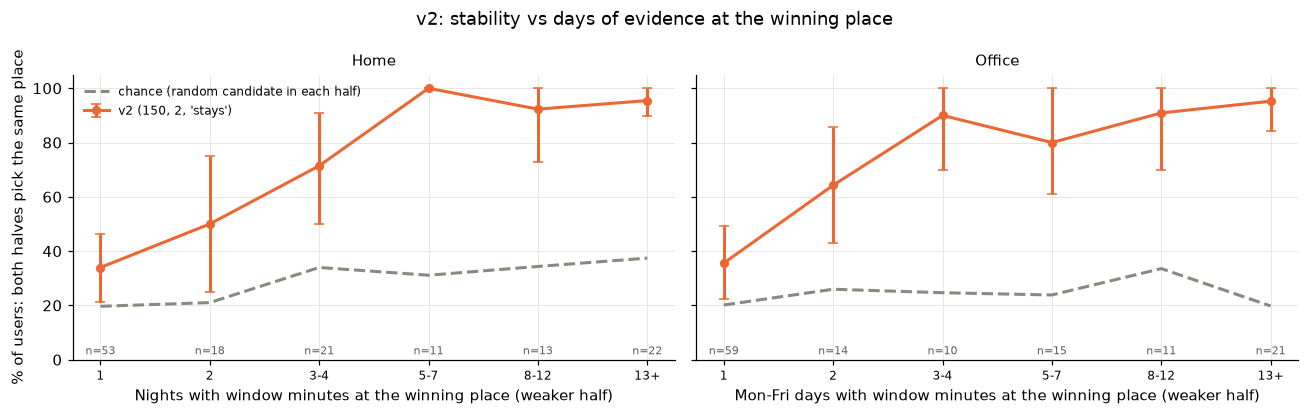

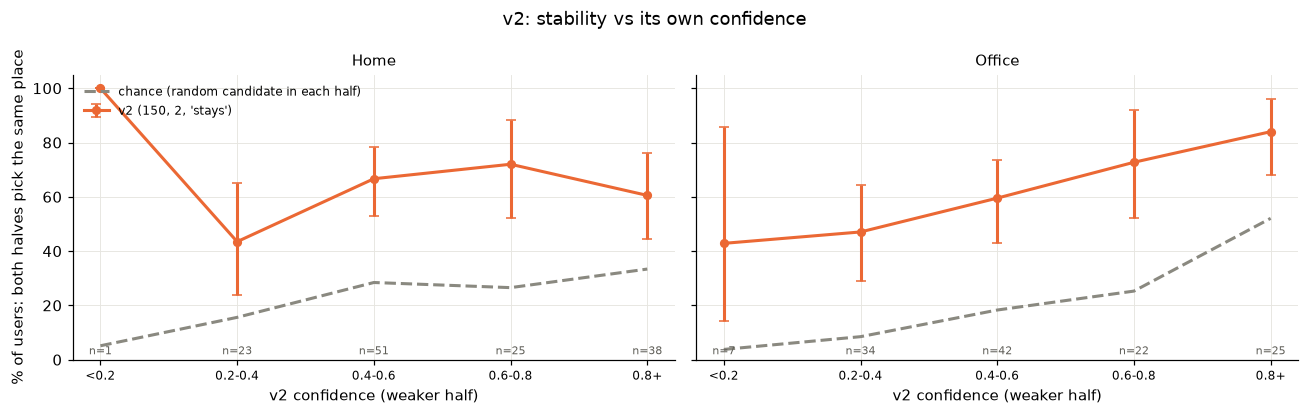

In [9]:
def curve(d, col, bins, labels):
    d = d.assign(bin=pd.cut(d[col], bins, right=False, labels=labels), same=d["same"].astype(bool))
    out = []
    for (kind, b), x in d.groupby(["type", "bin"], observed=True):
        out.append({"type": kind, "bin": b, **boot(x), "chance": x["chance"].mean()})
    t = pd.DataFrame(out)
    t["bin"] = pd.Categorical(t["bin"], categories=labels, ordered=True)
    return t.sort_values(["type", "bin"])


def plot_curve(tab, xlabel, title, fname):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
    for ax, kind in zip(axes, TYPES):
        t = tab[tab["type"] == kind].set_index("bin").reindex(tab["bin"].cat.categories)
        x = np.arange(len(t))
        ax.errorbar(x, t["stable"] * 100, yerr=[(t["stable"] - t["ci_lo"]) * 100, (t["ci_hi"] - t["stable"]) * 100],
                    color="#eb6834", linewidth=2, marker="o", markersize=5, capsize=3, label=f"v2 {CHOSEN}")
        ax.plot(x, t["chance"] * 100, color=REF_COLORS["chance"], linewidth=2, linestyle="--",
                label="chance (random candidate in each half)")
        for i, n in enumerate(t["pairs"]):
            if pd.notna(n):
                ax.annotate(f"n={int(n)}", (i, 2), ha="center", fontsize=7, color="#5f5e58")
        ax.set_xticks(x, [str(b) for b in t.index], fontsize=8)
        ax.set_ylim(0, 105)
        ax.set_xlabel(xlabel[kind])
        ax.set_title(kind.capitalize(), fontsize=10)
    axes[0].set_ylabel("% of users: both halves pick the same place")
    axes[0].legend(loc="upper left", frameon=False, fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(FIG_DIR / fname)
    plt.show()


main = chosen[(chosen["split"] == "alt_day") & chosen["both_halves"]].merge(
    ref[ref["split"] == "alt_day"][["user_id", "type", "chance"]], on=["user_id", "type"])

MIN_BINS = [0, 240, 600, 1200, 2400, 4800, 9600, 1e9]
MIN_LABELS = ["<4 h", "4-10 h", "10-20 h", "20-40 h", "40-80 h", "80-160 h", "160 h+"]
by_min = curve(main, "win_min", MIN_BINS, MIN_LABELS)
by_min.round(3).to_csv(TABLE_DIR / "v2_stability_by_place_minutes.csv", index=False)
plot_curve(by_min, {k: "Window minutes of the winning place (weaker half)" for k in TYPES},
           "v2: stability vs the winning place's minutes in the window", "fig04_v2_stability_by_place_minutes.png")

DAY_BINS, DAY_LABELS = [1, 2, 3, 5, 8, 13, 10_000], ["1", "2", "3-4", "5-7", "8-12", "13+"]
by_days = curve(main, "days", DAY_BINS, DAY_LABELS)
by_days.round(3).to_csv(TABLE_DIR / "v2_stability_by_place_days.csv", index=False)
plot_curve(by_days, {"home": "Nights with window minutes at the winning place (weaker half)",
                     "office": "Mon-Fri days with window minutes at the winning place (weaker half)"},
           "v2: stability vs days of evidence at the winning place", "fig05_v2_stability_by_place_days.png")

CONF_BINS, CONF_LABELS = [0, 0.2, 0.4, 0.6, 0.8, 1.01], ["<0.2", "0.2-0.4", "0.4-0.6", "0.6-0.8", "0.8+"]
by_conf = curve(main, "conf", CONF_BINS, CONF_LABELS)
by_conf.round(3).to_csv(TABLE_DIR / "v2_stability_by_confidence.csv", index=False)
plot_curve(by_conf, {k: "v2 confidence (weaker half)" for k in TYPES},
           "v2: stability vs its own confidence", "fig06_v2_stability_by_confidence.png")

## 6. Ảnh hưởng trên toàn bộ dữ liệu
Áp các luật "unknown" ứng viên lên bằng chứng của nơi thắng trên **toàn bộ dữ liệu** mỗi user (cách notebook 13 làm cho v1). Hai dòng cuối là v1 của `src/` hiện tại (notebook 13) để so.

In [10]:
GATES = {
    "no candidate (no gate)": lambda f: pd.Series(False, index=f.index),
    "place < 240 window minutes": lambda f: f["full_win_min"] < 240,
    "place on < 2 days": lambda f: f["full_days"] < 2,
    "place on < 3 days": lambda f: f["full_days"] < 3,
    "< 240 min or < 2 days": lambda f: (f["full_win_min"] < 240) | (f["full_days"] < 2),
    "< 240 min or < 3 days": lambda f: (f["full_win_min"] < 240) | (f["full_days"] < 3),
}
full = chosen[chosen["split"] == "alt_day"].drop_duplicates(["user_id", "type"])
users_no_split = set(USERS) - set(full["user_id"])
extra = []
for u in users_no_split:                       # user chỉ có stay trong một ngày: không có cặp split-half
    g = USERS[u]
    pid = cluster(u, g, *CHOSEN)
    for kind in TYPES:
        p = pick_place(g, pid, kind)
        extra.append({"user_id": u, "type": kind, "found_full": p is not None,
                      **({f"full_{k}": p[k] for k in ("win_min", "days")} if p else {})})
full = pd.concat([full, pd.DataFrame(extra)], ignore_index=True)

rows = []
for kind, d in full.groupby("type"):
    f = d[d["found_full"].astype(bool)]
    for name, unknown in GATES.items():
        u = unknown(f)
        rows.append({"type": kind, "unknown_rule": name, "users": len(d), "answered": int((~u).sum()),
                     "unknown": int(len(d) - (~u).sum())})
for kind, n in (("home", 104), ("office", 100)):
    rows.append({"type": kind, "unknown_rule": "v1 in src/ (notebook 13, for comparison)", "users": len(USERS),
                 "answered": n, "unknown": len(USERS) - n})
impact = pd.DataFrame(rows)
impact.to_csv(TABLE_DIR / "v2_unknown_rule_impact.csv", index=False)
impact

,type,unknown_rule,users,answered,unknown
0,home,no candidate (no gate),174,164,10
1,home,place < 240 window minutes,174,138,36
2,home,place on < 2 days,174,115,59
3,home,place on < 3 days,174,104,70
4,home,< 240 min or < 2 days,174,114,60
5,home,< 240 min or < 3 days,174,104,70
6,office,no candidate (no gate),174,159,15
7,office,place < 240 window minutes,174,132,42
8,office,place on < 2 days,174,108,66
9,office,place on < 3 days,174,94,80


## 7. Kết luận

**Đã kiểm chứng trên dữ liệu** (174 user có stay, 18.597 stay ≥ 30 phút; 140 nhóm độc lập sau khi gộp các user dùng chung file; split chính `alt_day`, kiểm tra lại bằng `chrono`):

1. **Cài đặt DBSCAN của notebook khớp sklearn**: cùng stay lõi, cùng tập nhiễu, cùng phân hoạch lõi ở 522 / 522 trường hợp kiểm tra (chế độ đếm theo stay).
2. **Độ ổn định không chọn được `eps`** (Hình 1). Từ 100 m trở lên mọi cấu hình ở 55–68%, CI chồng nhau; chỉ `eps = 50 m` và `min_samples = 5` thấp hơn thấy rõ.
3. **`eps` lớn làm nơi rộng ra và nối các nơi khác nhau** (Hình 2, 3). P90 bán kính nơi thắng 275 → 949 m khi `eps` 100 → 500 m. Tỉ lệ home và office chung một cụm 22% (100 m), 29% (150 m), 31% (200 m), 37% (300 m), 42% (500 m), so với mốc "ở và làm cùng chỗ" thật 26–28%.
4. **Đếm `min_samples` theo số ngày không giúp phân cụm.** Độ ổn định bằng hoặc thấp hơn cách đếm theo stay ở cùng tham số; nó chỉ giảm nhẹ việc nối. Vì stay nhiễu được giữ thành nơi riêng, `min_samples` chỉ còn quyết định việc nối (1 và 2 theo stay cho kết quả giống hệt).
5. **Cấu hình chọn: `eps = 150 m`, `min_samples = 2`, đếm theo stay.** Đây là `eps` nhỏ nhất mà cả home và office đạt mức ổn định của vùng 200 m, với mức nối ngang mốc thật. Lựa chọn hợp lý, không tối ưu (chỉ số phẳng trong 100–200 m).
6. **v2 ổn định hơn v1 rõ rệt** (bảng `chosen_vs_v1.csv`):

   | Cách chia | Loại | v2 | vùng 200 m | v1 | ngẫu nhiên |
   |---|---|---|---|---|---|
   | `alt_day` | home | 62% (CI 53–70%) | 63% | 41% | 27% |
   | `alt_day` | office | 62% (CI 53–71%) | 63% | 42% | 23% |
   | `chrono` | home | 48% (CI 40–56%) | 47% | 37% | 26% |
   | `chrono` | office | 51% (CI 42–60%) | 50% | 35% | 22% |

   CI của v2 và v1 không chồng nhau ở `alt_day`. v2 ngang vùng 200 m, tức là đạt được cái lợi mà notebook 12, 13 đã dự đoán.
7. **Với v2, có thêm dữ liệu thì có thêm độ ổn định** (Hình 4, 5), khác với v1 ở notebook 13:
   - theo **số ngày** có phút trong khung tại nơi thắng (nửa yếu hơn): 1 ngày 34% / 36% (mốc ngẫu nhiên 20% / 20%, CI 21–46% / 22–49%); 2 ngày 50% / 64% (CI rộng 25–75% / 43–86%, 14–18 cặp); 3–4 ngày 71% / 90%; từ 5 ngày 80–100%;
   - theo **số phút** của nơi thắng: < 4 h 25% / 22% (mốc 14% / 14%, CI 11–41% / 9–33%); từ 20 h trở lên 83–100%. Home có một chỗ trũng ở 10–20 h (40%, 30 cặp), thường là nơi chỉ có 1–2 đêm.
8. **Confidence của v2 báo được một phần, nhưng không đều.** Office tăng theo confidence (47% ở 0,2–0,4 → 84% ở ≥ 0,8); home thì không (ô ≥ 0,8 chỉ 61%, thấp hơn 0,6–0,8). Không dùng làm ngưỡng unknown.
9. **Ảnh hưởng của luật unknown trên toàn bộ dữ liệu** (bảng `v2_unknown_rule_impact.csv`, 174 user có stay):

   | Luật unknown | Home trả lời | Office trả lời |
   |---|---|---|
   | chỉ khi không có ứng viên | 164 | 159 |
   | nơi < 240 phút trong khung | 138 | 132 |
   | nơi có < 2 ngày | 115 | 108 |
   | **< 240 phút hoặc < 2 ngày** | **114** | **108** |
   | < 240 phút hoặc < 3 ngày | 104 | 94 |
   | v1 trong `src/` hiện tại (notebook 13) | 104 | 100 |

**Đề xuất cho `src/` (chờ duyệt):**
- `ClusterClassifier` (v2): DBSCAN haversine trên stay của mỗi user với `eps_meters = 150`, `min_samples = 2`; stay nhiễu là nơi riêng (không bỏ dữ liệu). Điểm của nơi = tổng phút trong khung (dùng lại `window_minutes` của v1); hoà thì tổng thời lượng dài hơn, rồi đến sớm hơn. Vị trí = tâm có trọng số theo thời lượng; confidence = điểm nơi thắng / tổng điểm.
- Unknown của v2: nơi thắng có **< 240 phút** trong khung (`too_few_window_minutes`, giống v1) **hoặc** có phút trong khung ở **< 2 ngày** khác nhau (`one_off_place`, bản tương ứng của `support < 2` ở v1, nhưng đếm ngày). 2 ngày chưa đủ dữ liệu để kết luận, nên chọn ngưỡng thấp nhất có bằng chứng (1 ngày ≈ ngẫu nhiên), như notebook 13. Kết quả: home 114, office 108 user, nhiều hơn v1 (104 / 100) và ổn định hơn.
- POI của v2: các nơi (cụm) không chạm khung nào, xếp theo tổng thời lượng. Cùng một cách gộp cho home, office và POI, thay cho geohash 6 ký tự (~1 km) của v1.
- `configs/*.yaml`: `clustering.eps_meters = 150`, `min_samples = 2`, trích notebook 14.

**Chưa kiểm chứng / giới hạn:**
- Độ ổn định là **tính nhất quán, không phải độ đúng**; không có nhãn home/office thật.
- `eps` được chọn trên một chỉ số phẳng; 100–200 m đều bảo vệ được. Mốc "ở và làm cùng chỗ" (26–28%) chính nó dựa trên bán kính 200 m.
- Ngưỡng unknown đo trên **một nửa** dữ liệu rồi áp cho toàn bộ, như notebook 13. Các ô 2 ngày và 4–10 h có 13–29 cặp, CI rộng.
- "Ngày" khi đếm là ngày có phút trong khung tại nơi đó (đêm của ngày *d* là 22 h ngày *d* → 08 h ngày *d*+1), không phải ngày đến.